<a href="https://colab.research.google.com/github/bsheese/387/blob/main/22_images/22_2_Autoencoders_and_Diffusion/22_2_1_Denoising_Autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Images: Part 5
## A Denoising Autoencoder

---

## What This Notebook Is About

Every image model in this course so far has taken an image in and given a label out: a breed, or one of the ten Fashion-MNIST classes. This notebook and the next one turn that around and have the network produce an image.

The network here is an **autoencoder**. It squeezes an image down to a short list of numbers and then rebuilds the image from that list. We train it as a **denoising** autoencoder: it gets an image with random noise added and has to rebuild the clean image. Nobody tells it what class any image is, so everything it learns comes from the pictures themselves.

Removing noise is also the idea behind the image generators that 22_2_2 looks at. This notebook ends by showing where a one-step denoiser runs out of ability, which is the problem those generators solve.

**What you will learn:**
1. How to add random noise to images, and what it does to them
2. How an autoencoder is built: an **encoder** that shrinks the image to a short **code**, and a **decoder** that rebuilds an image from the code
3. How to train it with the clean image as the target, and how to check it against simple baselines
4. What the 32-number code captures, even though the network never saw a label
5. Why the decoder can't make convincing new images from made-up codes, and what happens to a denoiser when the noise is heavier than it was trained on

The training cell takes seconds on Colab's GPU (Runtime → Change runtime type → T4 GPU) and about 3 to 4 minutes on Colab's CPU. The notebook is saved with its outputs, so you can read the results before running anything.

In [1]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from torch import nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
torch.manual_seed(0)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    # It saves to a temporary name first, so a download that fails partway doesn't leave a broken file behind.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name + '.part')
        os.replace(name + '.part', name)
    return name

data = np.load(fetch('fashion10k.npz'))
CLASSES = list(data['classes'])

def prepare(images):
    # (number of images, 1 channel, 28, 28), values 0 to 1
    return torch.tensor(images[:, None] / 255, dtype=torch.float32)

X_train, X_val, X_test = prepare(data['x_train']), prepare(data['x_val']), prepare(data['x_test'])
y_test = data['y_test']
print('X_train:', tuple(X_train.shape), '  X_val:', tuple(X_val.shape), '  X_test:', tuple(X_test.shape))

device: cpu
X_train: (10000, 1, 28, 28)   X_val: (5000, 1, 28, 28)   X_test: (10000, 1, 28, 28)


These are the same Fashion-MNIST images as in units 21 and 22_0. This time the labels are only kept for the test images, and only so that we can check later what the network learned. Training never uses a label.

---

## Section 1: Adding Noise

To make a noisy copy of an image, we add a random number to every pixel. `torch.randn` gives random numbers from the **normal distribution** with mean 0 and standard deviation 1, the bell curve: most of the numbers are between −1 and 1, and a few are larger. Multiplying them by `NOISE = 0.5` makes them half as large. Pixel values run from 0 (black) to 1 (white), so a change of 0.5 is large. Adding the noise can push a pixel below 0 or above 1, and `.clamp(0, 1)` puts those back at the nearest end of the range.

The validation and test images get their noise once, from a random number generator with a fixed seed. That way they keep the same noise for the whole notebook, and every comparison below is on the same noisy images.

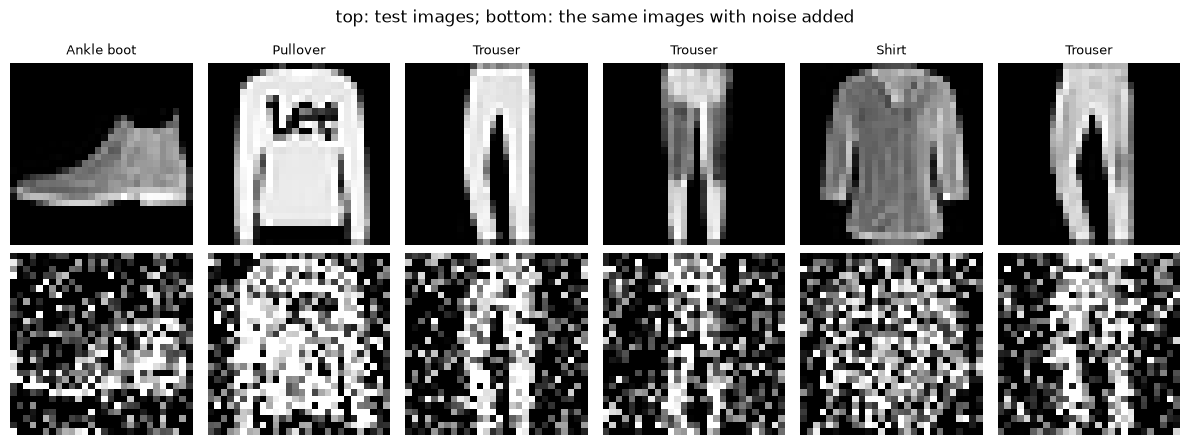

In [2]:
NOISE = 0.5

def add_noise(x, amount=NOISE, generator=None):
    # Add a random number from the bell curve, times amount, to every pixel; keep values between 0 and 1.
    noise = torch.randn(x.shape, generator=generator)
    return (x + amount * noise).clamp(0, 1)

g = torch.Generator().manual_seed(1)
X_val_noisy = add_noise(X_val, generator=g)
X_test_noisy = add_noise(X_test, generator=g)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for j in range(6):
    axes[0, j].imshow(X_test[j, 0], cmap='gray', vmin=0, vmax=1)
    axes[0, j].set_title(CLASSES[y_test[j]], fontsize=9)
    axes[1, j].imshow(X_test_noisy[j, 0], cmap='gray', vmin=0, vmax=1)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('top: test images; bottom: the same images with noise added')
plt.tight_layout()
plt.show()

The garments are still recognizable to a person, because we can see the overall shape through the noise, but the fine detail is gone: the edges are ragged, and the dark background is full of bright speckles. The job for the network is to get the top row back from the bottom row.

---

## Section 2: An Encoder and a Decoder

An autoencoder has two halves.

- The **encoder** is a CNN like 22_0_2's: two blocks of convolution, ReLU and max pooling shrink the 28 × 28 image to 7 × 7 while adding channels. Then a linear layer turns the 32 × 7 × 7 = 1,568 numbers into just 32 numbers. Those 32 numbers are the image's **code**. The narrow point in the middle of the network where the code sits is called the **bottleneck**.
- The **decoder** runs the other way. A linear layer turns the 32 numbers back into 32 channels of 7 × 7, and two **transposed convolutions** (`nn.ConvTranspose2d`) make the image larger again. With a kernel size of 2 and a stride of 2, a transposed convolution turns every pixel into a 2 × 2 block, using learned weights to decide what goes in the block, so it doubles the width and height. That is the opposite of what max pooling did in the encoder. A sigmoid at the end (19_1_3) keeps every output pixel between 0 and 1.

The network has to rebuild 784 pixels from 32 numbers. It can't copy the input through, so it has to learn what Fashion-MNIST images generally look like and keep only what distinguishes one image from another.

In [3]:
class Autoencoder(nn.Module):
    def __init__(self, code_size=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 28 x 28 -> 14 x 14
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 14 x 14 -> 7 x 7
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, code_size),                                # 1,568 numbers -> the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(code_size, 32 * 7 * 7), nn.ReLU(),                     # the code -> 1,568 numbers
            nn.Unflatten(1, (32, 7, 7)),                                     # back into 32 channels of 7 x 7
            nn.ConvTranspose2d(32, 16, 2, stride=2), nn.ReLU(),             # 7 x 7 -> 14 x 14
            nn.ConvTranspose2d(16, 1, 2, stride=2), nn.Sigmoid(),           # 14 x 14 -> 28 x 28, values 0 to 1
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

model = Autoencoder().to(device)

# Follow one image through the network, layer by layer
x = X_test_noisy[:1].to(device)
print(f"{'input':16} {tuple(x.shape)}")
with torch.no_grad():
    for layer in list(model.encoder) + list(model.decoder):
        x = layer(x)
        print(f'{layer.__class__.__name__:16} {tuple(x.shape)}')
print(f'\nweights: {sum(p.numel() for p in model.parameters()):,}')

input            (1, 1, 28, 28)
Conv2d           (1, 16, 28, 28)
ReLU             (1, 16, 28, 28)
MaxPool2d        (1, 16, 14, 14)
Conv2d           (1, 32, 14, 14)
ReLU             (1, 32, 14, 14)
MaxPool2d        (1, 32, 7, 7)
Flatten          (1, 1568)
Linear           (1, 32)
Linear           (1, 1568)
ReLU             (1, 1568)
Unflatten        (1, 32, 7, 7)
ConvTranspose2d  (1, 16, 14, 14)
ReLU             (1, 16, 14, 14)
ConvTranspose2d  (1, 1, 28, 28)
Sigmoid          (1, 1, 28, 28)

weights: 108,881


The shapes go down and back up: (1, 1, 28, 28) shrinks to a code of shape (1, 32) after the encoder's `Linear` layer, and the decoder brings it back to (1, 1, 28, 28), the same shape as the input. Most of the weights are in the two linear layers next to the bottleneck, each of which connects 1,568 numbers to 32.

---

## Section 3: Training with the Clean Image as the Target

The training loop is unit 21's, with two changes.

- **The input is noisy and the target is clean.** For a classifier, the target was a label. Here the target is the clean version of the input image, and the loss compares the network's output with it pixel by pixel. The loss is the **mean squared error** from 20_0_3: the average, over every pixel, of the squared difference between the output and the clean image.
- **The noise is new every time.** `add_noise` is called on every batch, so an image gets different noise each time it comes round. Like augmentation in 22_0_2, this gives the network many more training examples than there are images, and it can't learn any particular noise pattern by heart.

The validation loss is measured on the fixed noisy validation images after each epoch.

In [4]:
EPOCHS = 10
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train), batch_size=64, shuffle=True)

history = {'train': [], 'val': []}
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for (clean,) in loader:
        noisy = add_noise(clean)                       # new noise every time an image is used
        clean, noisy = clean.to(device), noisy.to(device)
        loss = loss_fn(model(noisy), clean)            # compare the output with the CLEAN image
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(clean)
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_noisy.to(device)), X_val.to(device)).item()
    history['train'].append(total / len(X_train))
    history['val'].append(val_loss)
    print(f"epoch {epoch:2}:  training loss {history['train'][-1]:.4f}   validation loss {val_loss:.4f}")

epoch  1:  training loss 0.0908   validation loss 0.0442


epoch  2:  training loss 0.0331   validation loss 0.0288


epoch  3:  training loss 0.0267   validation loss 0.0256


epoch  4:  training loss 0.0243   validation loss 0.0238


epoch  5:  training loss 0.0228   validation loss 0.0226


epoch  6:  training loss 0.0218   validation loss 0.0219


epoch  7:  training loss 0.0211   validation loss 0.0213


epoch  8:  training loss 0.0205   validation loss 0.0208


epoch  9:  training loss 0.0201   validation loss 0.0202


epoch 10:  training loss 0.0196   validation loss 0.0198


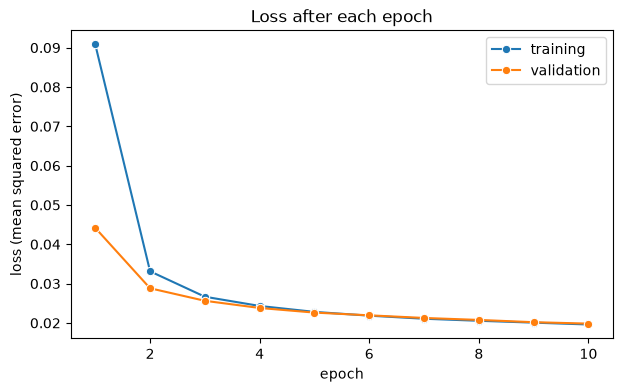

In [5]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4))
sns.lineplot(x=epochs, y=history['train'], marker='o', label='training')
sns.lineplot(x=epochs, y=history['val'], marker='o', label='validation')
plt.xlabel('epoch')
plt.ylabel('loss (mean squared error)')
plt.title('Loss after each epoch')
plt.show()

Both losses drop steeply in the first three epochs, from 0.0442 to 0.0256 on the validation images, and then keep falling slowly, reaching 0.0198 after epoch 10. The first epoch's training loss (0.0908) is much higher than its validation loss because it is the average over the whole epoch, including the early batches when the network was still producing near-random images, while the validation loss is measured at the end of the epoch. From epoch 3 on the two losses are within a few thousandths of each other, so the network isn't overfitting: with fresh noise every time, it never sees exactly the same input twice.

A loss of 0.0198 means that the average squared difference between an output pixel and the clean pixel is about 0.02, so a typical pixel is off by roughly the square root of that, about 0.14 on the 0 to 1 scale.

---

## Section 4: Is It Any Good?

A loss on its own doesn't say much, so we compare it with two baselines (19_1_1), both measured on the noisy test images:

- **Do nothing**: hand back the noisy image unchanged. Any denoiser has to beat this.
- **Blur it**: replace every pixel with the average of the 3 × 3 patch around it, the blur filter from 22_0_1. Averaging neighbouring pixels cancels out much of the random noise, because the noise added to neighbouring pixels is independent, but it also smears the real edges. It needs no training at all.

The cell builds the blur filter as a `Conv2d` layer with all nine weights set to 1/9.

noisy image, unchanged   test loss (MSE) 0.1178
blur filter              test loss (MSE) 0.0462
autoencoder              test loss (MSE) 0.0198


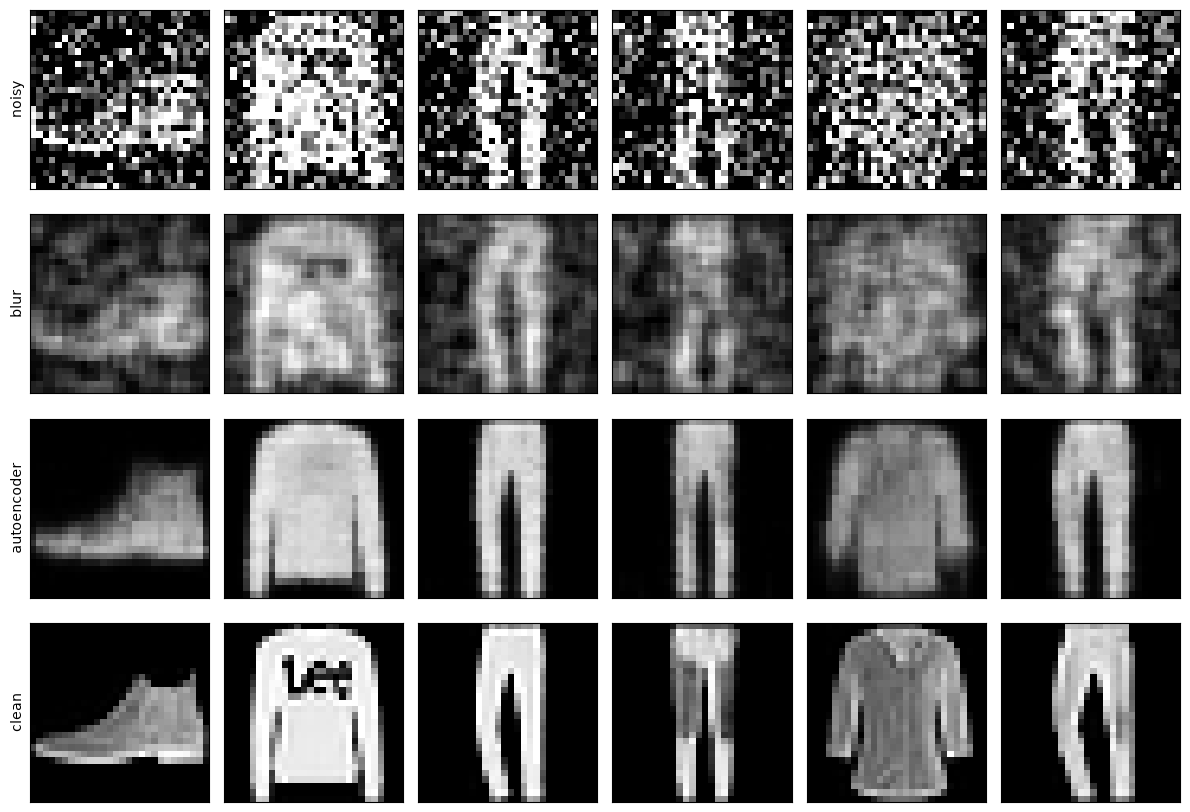

In [6]:
blur = nn.Conv2d(1, 1, 3, padding=1, bias=False)
with torch.no_grad():
    blur.weight[:] = 1 / 9                           # 22_0_1's blur filter: the average of each 3 x 3 patch
    X_test_blur = blur(X_test_noisy)
    X_test_denoised = model(X_test_noisy.to(device)).cpu()

for name, images in [('noisy image, unchanged', X_test_noisy), ('blur filter', X_test_blur),
                     ('autoencoder', X_test_denoised)]:
    print(f'{name:24} test loss (MSE) {loss_fn(images, X_test).item():.4f}')

rows = [('noisy', X_test_noisy), ('blur', X_test_blur), ('autoencoder', X_test_denoised), ('clean', X_test)]
fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
for r, (name, images) in enumerate(rows):
    for j in range(6):
        axes[r, j].imshow(images[j, 0], cmap='gray', vmin=0, vmax=1)
        axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
    axes[r, 0].set_ylabel(name)
plt.tight_layout()
plt.show()

The autoencoder's test loss (0.0198) is less than half the blur filter's (0.0462) and about a sixth of the loss of leaving the noise in (0.1178), so it is doing much more than averaging neighbouring pixels.

The images show where the difference comes from. The blur filter removes the speckles but leaves a grey haze over the background and smears the edges, because it treats every patch of every image the same way. The autoencoder gives clean black backgrounds and sharp outlines, because it has learned what shapes Fashion-MNIST garments have. What it loses is fine detail. Compare the pullover in the second column with its clean version: the "Lee" logo is gone, and the autoencoder's pullover is a plain light shape. The trousers lose their texture, and the garment in the fifth column becomes a generic long-sleeved top. The 32-number code has room for the overall shape and brightness of a garment, but not for small details that only a few images have.

---

## Section 5: What Is in the 32 Numbers?

The network was never told which class any image belongs to. But to rebuild a garment from 32 numbers, the code has to say something about what kind of garment it is: a sandal and a coat need very different pixels. One way to check is to compute the code of every clean test image and, for each one, find the test image whose code is **closest** (the smallest distance between the two lists of 32 numbers, `torch.cdist`). If similar garments get similar codes, the closest code should usually belong to an image of the same class.

codes: (10000, 32)
the closest code belongs to the same class: 0.776 of the time
  Coat / Pullover: 352
  Shirt / T-shirt/top: 345
  Pullover / Shirt: 311
  Coat / Shirt: 240


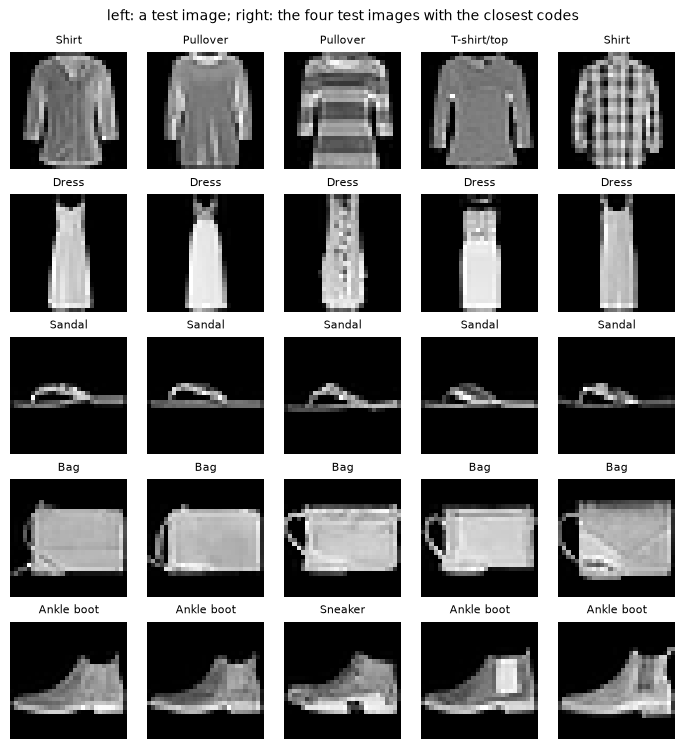

In [7]:
with torch.no_grad():
    codes = model.encoder(X_test.to(device)).cpu()        # each clean test image -> 32 numbers
print('codes:', tuple(codes.shape))

distances = torch.cdist(codes, codes)                     # distance between every pair of codes
distances.fill_diagonal_(float('inf'))                    # an image doesn't count as its own neighbour
nearest = distances.argmin(dim=1).numpy()
same_class = y_test[nearest] == y_test
print(f'the closest code belongs to the same class: {same_class.mean():.3f} of the time')

# The most common mix-ups, counted in both directions
pairs = {}
for a, b in zip(y_test[~same_class], y_test[nearest][~same_class]):
    key = tuple(sorted((CLASSES[a], CLASSES[b])))
    pairs[key] = pairs.get(key, 0) + 1
for (a, b), n in sorted(pairs.items(), key=lambda kv: -kv[1])[:4]:
    print(f'  {a} / {b}: {n}')

# A few test images (left) and the four test images with the closest codes
queries = [int(np.where(y_test == k)[0][0]) for k in [6, 3, 5, 8, 9]]   # shirt, dress, sandal, bag, ankle boot
fig, axes = plt.subplots(len(queries), 5, figsize=(7, 7.6))
for r, q in enumerate(queries):
    closest = distances[q].argsort()[:4].numpy()
    for c, i in enumerate([q] + list(closest)):
        axes[r, c].imshow(X_test[i, 0], cmap='gray', vmin=0, vmax=1)
        axes[r, c].set_title(CLASSES[y_test[i]], fontsize=8)
        axes[r, c].axis('off')
plt.suptitle('left: a test image; right: the four test images with the closest codes', fontsize=10)
plt.tight_layout()
plt.show()

The closest code belongs to an image of the same class 77.6% of the time. Compare that with what chance would give: with ten classes of equal size, a random test image is of the same class about 10% of the time. The network was never told the classes, so this structure in the codes comes only from what it needed to rebuild the images.

The most common mix-ups are coat and pullover (352), shirt and T-shirt/top (345), pullover and shirt (311) and coat and shirt (240). Those are the upper-body classes, the same ones that the classifiers in 21_1_2 and 22_0_2 confused most, which makes sense: the codes are similar when the pictures are similar, and these garments look alike at 28 × 28 pixels.

The grid shows the same thing for a few examples. The dress, sandal and bag all have four neighbours of their own class, and the neighbours look very much like them (the sandals are all flat, strappy shapes facing the same way). The shirt's closest codes belong to two pullovers, a T-shirt/top and one other shirt, all long-sleeved tops of about the same brightness. The ankle boot's include a sneaker with a high ankle.

---

## Section 6: Can the Decoder Make New Images?

The decoder turns any 32 numbers into an image. So we could try giving it codes that didn't come from a real image and see whether it makes new garments. Two experiments:

- **In between two codes.** Take the code of a pair of trousers and the code of a sneaker, and decode points along the straight line between them: 0% of the way, 1/7 of the way, and so on up to 100%.
- **Made-up codes.** Pick 32 random numbers, scaled so that each one has the same average and spread as that position does across the real codes, and decode them.

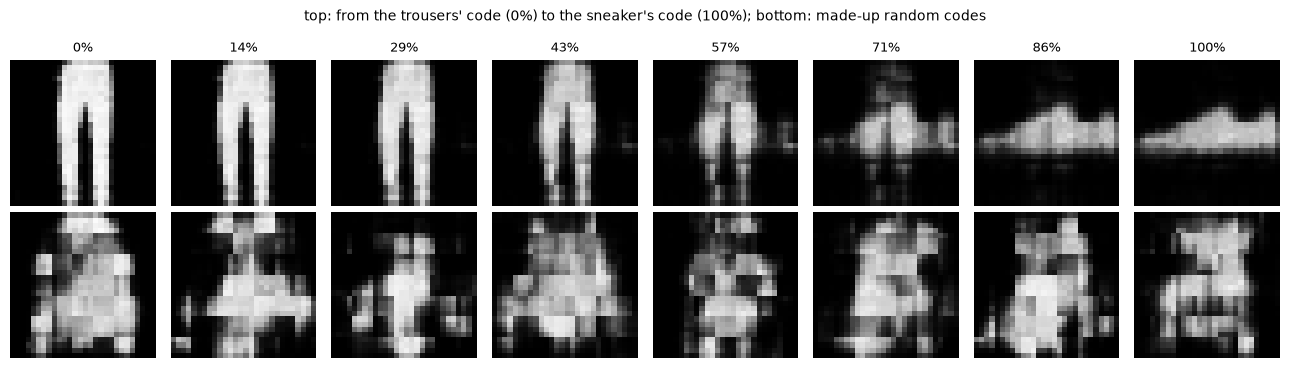

In [8]:
trouser = int(np.where(y_test == 1)[0][0])
sneaker = int(np.where(y_test == 7)[0][0])
a, b = codes[trouser], codes[sneaker]
steps = torch.linspace(0, 1, 8)
between = torch.stack([a + (b - a) * t for t in steps])       # 8 codes on the line from a to b

torch.manual_seed(2)
made_up = codes.mean(dim=0) + codes.std(dim=0) * torch.randn(8, 32)   # random codes with the real codes' average and spread

with torch.no_grad():
    images_between = model.decoder(between.to(device)).cpu()
    images_made_up = model.decoder(made_up.to(device)).cpu()

fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for j in range(8):
    axes[0, j].imshow(images_between[j, 0], cmap='gray', vmin=0, vmax=1)
    axes[0, j].set_title(f'{steps[j]:.0%}', fontsize=9)
    axes[1, j].imshow(images_made_up[j, 0], cmap='gray', vmin=0, vmax=1)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('top: from the trousers\' code (0%) to the sneaker\'s code (100%); bottom: made-up random codes', fontsize=10)
plt.tight_layout()
plt.show()

In the top row, the first four images (0% to 43% of the way) are still trousers, slowly getting fainter. At 57% the image is a smudge with features of both, and from 71% on it turns into a blurred sneaker. The points in between don't show some garment halfway between trousers and a sneaker; they show a blend of the two pictures, the kind of thing you'd get by fading one image into the other.

The made-up codes in the bottom row are worse. None of them looks like a real garment; they are blotchy shapes with some of the brightness and outline of a top or a bag. The real images' codes don't fill the whole space of possible lists of 32 numbers. They are bunched in some regions, and a random list mostly lands outside those regions, where the decoder was never trained and produces something that isn't a garment.

So the decoder can rebuild images from codes that came from real images, but it can't be used on its own to make new ones. The autoencoder was trained to compress and rebuild, and nothing in its training asked it to make sense of codes that no image produced.

---

## Section 7: More Noise Than It Was Trained On

The autoencoder was trained with `NOISE = 0.5`. The last experiment gives it heavier noise, 1.0 and 2.0, and finally an image of pure noise with no garment in it at all (`torch.rand`, every pixel a random value between 0 and 1).

noise 0.5:  test loss (MSE) on these 4 images 0.0179
noise 1.0:  test loss (MSE) on these 4 images 0.0475
noise 2.0:  test loss (MSE) on these 4 images 0.1085


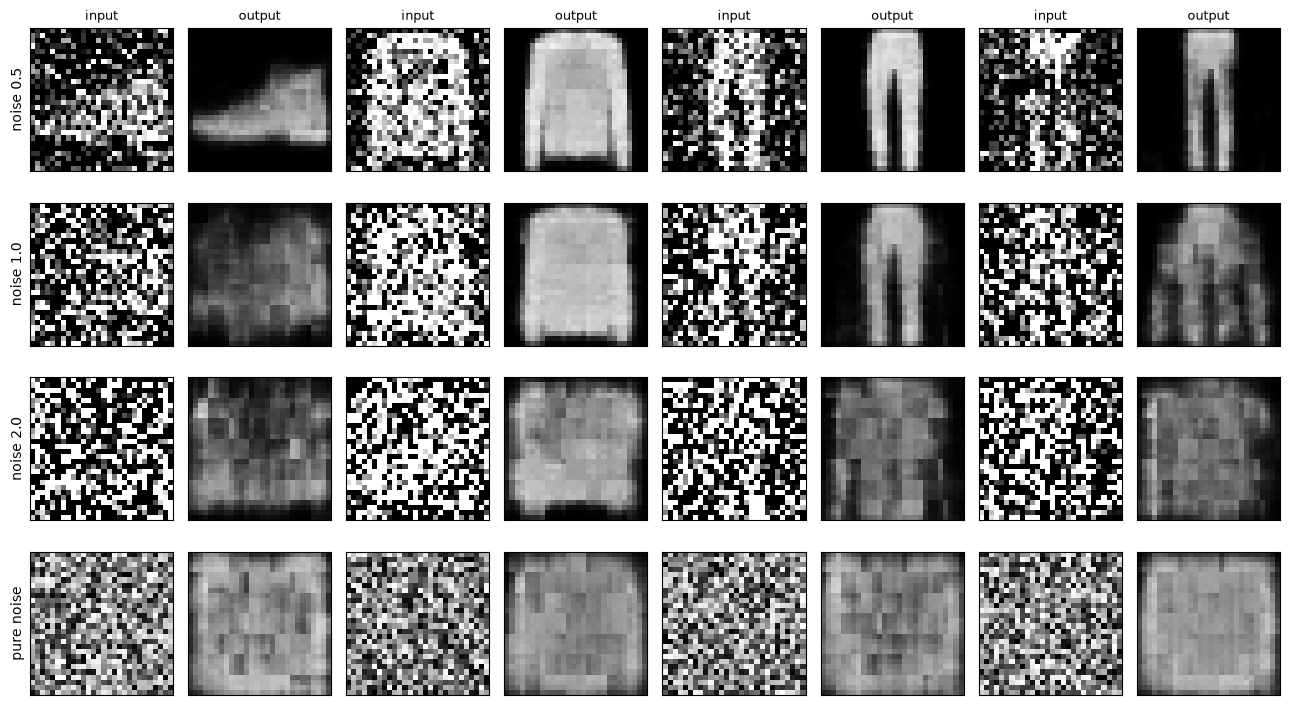

In [9]:
g = torch.Generator().manual_seed(3)
levels = [0.5, 1.0, 2.0]
noisy_versions = {amount: add_noise(X_test[:4], amount, generator=g) for amount in levels}
noisy_versions['pure noise'] = torch.rand((4, 1, 28, 28), generator=g)

with torch.no_grad():
    outputs = {k: model(v.to(device)).cpu() for k, v in noisy_versions.items()}
for amount in levels:
    print(f'noise {amount}:  test loss (MSE) on these 4 images {loss_fn(outputs[amount], X_test[:4]).item():.4f}')

fig, axes = plt.subplots(4, 8, figsize=(13, 7.4))
for r, k in enumerate(noisy_versions):
    for j in range(4):
        axes[r, 2 * j].imshow(noisy_versions[k][j, 0], cmap='gray', vmin=0, vmax=1)
        axes[r, 2 * j + 1].imshow(outputs[k][j, 0], cmap='gray', vmin=0, vmax=1)
        axes[r, 2 * j].set_title('input' if r == 0 else '', fontsize=9)
        axes[r, 2 * j + 1].set_title('output' if r == 0 else '', fontsize=9)
    axes[r, 0].set_ylabel(f'noise {k}' if k != 'pure noise' else k)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

At the noise level it was trained on (0.5, top row), the outputs are the clean garments, as in Section 4. At 1.0 the outputs are worse: the pullover and the first pair of trousers are still right but blurrier, the ankle boot has become a dim blob, and the second pair of trousers comes out looking more like a top. The test loss on these four images goes from 0.0179 to 0.0475. At 2.0 (loss 0.1085, about as bad as leaving the noise in at 0.5), all four outputs are the same kind of grey, roughly top-shaped blur. From pure noise, the four outputs are almost identical to one another.

The reason is the loss. When the input is so noisy that the network can't tell which garment it came from, the output that gives the lowest average squared error is not any one garment, but a compromise between all of them: the average Fashion-MNIST image. A sharp guess that turned out to be wrong would cost much more than a blurred average. So a one-step denoiser trained with mean squared error can't produce a sharp image from heavy noise, and from pure noise it produces the same blur every time.

---

## Summary

- A **denoising autoencoder** is trained to rebuild a clean image from a noisy one. The input is the noisy image, the target is the clean image, and the loss is the mean squared error over the pixels. No labels are used.
- The **encoder** (convolutions, pooling and a linear layer) shrinks each 28 × 28 image to a **code** of 32 numbers at the **bottleneck**; the **decoder** (a linear layer and **transposed convolutions**) rebuilds a 28 × 28 image from the code.
- On the noisy test images, the autoencoder's mean squared error (0.0198) was less than half the blur filter's (0.0462) and about a sixth of leaving the noise in (0.1178). It recovers outlines and clean backgrounds but loses fine details such as a logo.
- For 77.6% of test images, the closest code belongs to an image of the same class, against about 10% by chance, although training never used a label. The mix-ups are mostly among the upper-body garments.
- Decoding codes that didn't come from real images gives blends and smudges rather than new garments. The autoencoder learned to compress and rebuild, not to generate.
- With heavier noise than it was trained on, and especially from pure noise, the output becomes a blurred, average-looking garment, because the mean squared error rewards a compromise between all the images the input could have come from.

## What's next

This notebook removed noise in one step, and that worked only when the noise was light. 22_2_2 looks at how image generators get around that limit. A **diffusion model** is trained to remove a small amount of noise from images at every level of noise, from nearly clean to pure noise. To make a new image, it starts from pure noise and removes a little at a time, hundreds of times, so that every step is an easy one like the light-noise case here. We use a pretrained diffusion model, step through its intermediate images, and finish with a model that makes an image from a text description.